# 03 · Evaluation on 2024 (out-of-time test)

1. Predictions on the test year
2. Compare every model
3. Calibration
4. What LightGBM uses
5. Fairness check: with vs. without gender
6. Risk tiers
7. Final model choice

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # make `src` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

from src.train import DISPLAY_NAMES, fit_all, usable_rows
from src.predict import predict_frame
from src.evaluate import (
    calibration_table, choose_model, comparison_table, lift_table, assign_risk_tier,
)

In [2]:
train = pd.read_csv(config.TRAIN_FILE)
test = usable_rows(pd.read_csv(config.TEST_FILE))

models = fit_all(train)
predictions = {name: predict_frame(name, model, test) for name, model in models.items()}
y = test[config.TARGET]
p_glm = predictions["glm"]
p_lgbm = predictions["lgbm"]

## 2. Compare the models

AUC is a sorting score. Higher means drivers who really claimed are placed above drivers who did not. The calibration gap checks the percentages: smaller means a predicted chance is close to what actually happened. About 15% of these 2024 policies had a claim.

![Six classifiers compared on 2024](../reports/figures/model_comparison.png)

In [3]:
scores = comparison_table(y, predictions)
shown = scores.rename(index=DISPLAY_NAMES)
print("Chosen model:", DISPLAY_NAMES[choose_model(scores)])
shown.round(3)

Chosen model: LightGBM


,AUC,Gini,Brier,calibration_gap,mean_predicted
GLM,0.679,0.359,0.121,0.005,0.149
Logistic regression,0.676,0.352,0.122,0.008,0.150
Decision tree,0.663,0.326,0.122,0.005,0.149
Random forest,0.679,0.359,0.122,0.019,0.149
XGBoost,0.683,0.366,0.121,0.003,0.150
LightGBM,0.692,0.384,0.120,0.003,0.150


,decile,policies,exposure,predicted_rate,actual_rate,lift
0,1,16786,2048.284932,0.022508,0.024783,0.163670
1,2,16785,6140.742466,0.057735,0.064701,0.427298
2,3,16785,10471.353425,0.089717,0.090080,0.594911
3,4,16785,13620.621918,0.113048,0.113971,0.752689
4,5,16786,14929.890411,0.129840,0.130883,0.864380
5,6,16785,15414.268493,0.144426,0.143402,0.947058
6,7,16785,15353.002740,0.162186,0.160739,1.061555
7,8,16785,15496.424658,0.192743,0.194876,1.287008
8,9,16785,16060.816438,0.238056,0.235270,1.553773
9,10,16786,16317.161644,0.346025,0.355475,2.347636


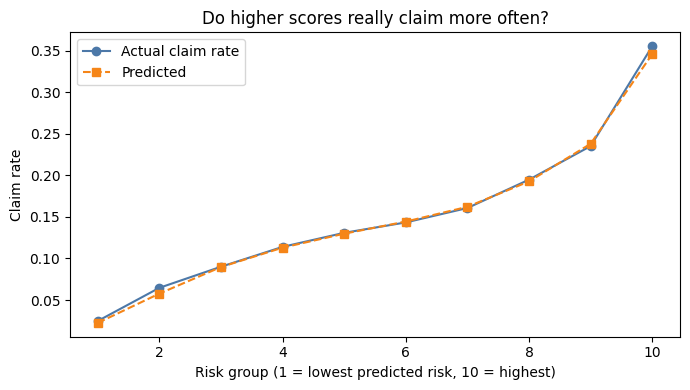

In [4]:
lift = lift_table(y, p_lgbm, test[config.EXPOSURE_COL])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lift["decile"].astype(int), lift["actual_rate"], "o-", color="#4C78A8", label="Actual claim rate")
ax.plot(lift["decile"].astype(int), lift["predicted_rate"], "s--", color="#F58518", label="Predicted")
ax.set_xlabel("Risk group (1 = lowest predicted risk, 10 = highest)")
ax.set_ylabel("Claim rate")
ax.set_title("Do higher scores really claim more often?")
ax.legend()
fig.tight_layout()
fig.savefig(Path("..") / "reports" / "figures" / "lift.png", dpi=150)
lift

## 3. Calibration

The app shows probabilities to users, so they need to be correct, not just well ranked.

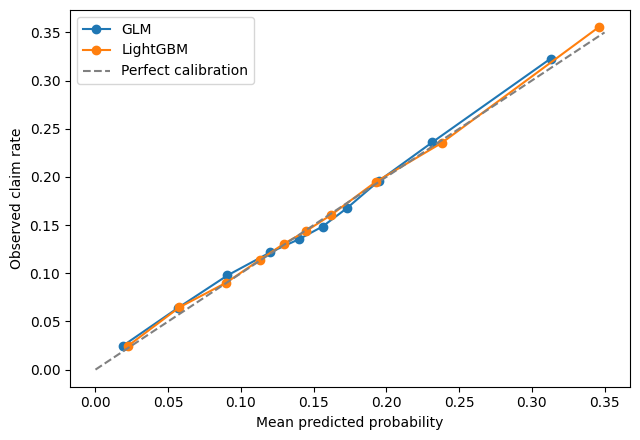

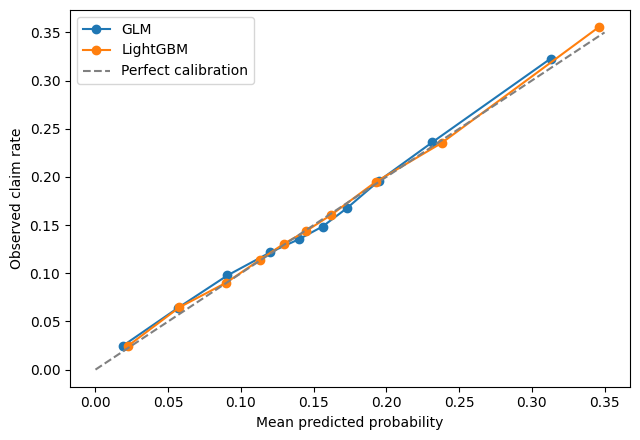

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label, pred in [("GLM", p_glm), ("LightGBM", p_lgbm)]:
    cal = calibration_table(y, pred)
    ax.plot(cal["predicted_rate"], cal["actual_rate"], "o-", label=label)
lim = [0, 0.35]
ax.plot(lim, lim, "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed claim rate")
ax.legend()
fig.tight_layout()
fig.savefig(Path("..") / "reports" / "figures" / "calibration.png", dpi=150)
fig

## 4. What LightGBM uses

The share below is how much each original fact contributed to the LightGBM splits, measured by gain. One-hot columns such as coverage = comprehensive are added back together, so the chart shows Coverage rather than one bar per code.

Time on cover is about half of the splits, because a policy that was in force for a short time has less chance to claim. The app fixes that at one full year. After that, coverage is the largest remaining fact (about 15%), then vehicle value (about 6%) and vehicle age (about 5%).

total_exposure           0.530
policy_type              0.151
vehicle_value            0.062
vehicle_age              0.047
power_to_weight_ratio    0.045
driver_age               0.035
payment_frequency        0.034
age_driving_licence      0.021
vehicle_brand            0.018
fuel_type                0.015
bonus_score              0.009
circulation_area         0.009
business_type            0.009
municipality_type        0.006
seats                    0.006
Name: share of splits, dtype: float64

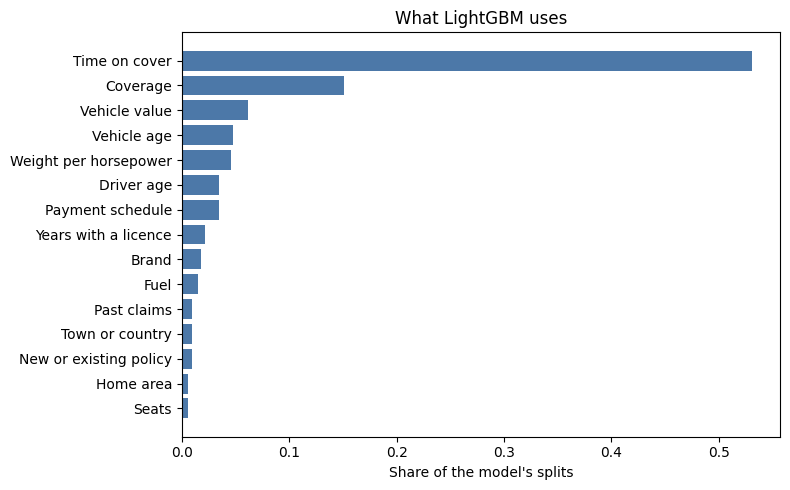

In [6]:
fitted = models["lgbm"].named_steps["model"]
raw_names = models["lgbm"].named_steps["preprocess"].get_feature_names_out()
gain = pd.Series(fitted.booster_.feature_importance(importance_type="gain"), index=raw_names)
columns = sorted(config.FEATURES + [config.EXPOSURE_COL], key=len, reverse=True)

def original(name):
    rest = name.split("__", 1)[1]
    if name.startswith("num__"):
        return rest
    for column in columns:
        if rest == column or rest.startswith(column + "_"):
            return column
    return rest

share = gain.groupby(gain.index.map(original)).sum()
share = (share / share.sum()).sort_values(ascending=False).rename("share of splits")

friendly = {
    "total_exposure": "Time on cover",
    "policy_type": "Coverage",
    "vehicle_value": "Vehicle value",
    "vehicle_age": "Vehicle age",
    "power_to_weight_ratio": "Weight per horsepower",
    "driver_age": "Driver age",
    "payment_frequency": "Payment schedule",
    "age_driving_licence": "Years with a licence",
    "vehicle_brand": "Brand",
    "fuel_type": "Fuel",
    "bonus_score": "Past claims",
    "circulation_area": "Town or country",
    "business_type": "New or existing policy",
    "municipality_type": "Home area",
    "seats": "Seats",
}
plot = share.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([friendly.get(name, name) for name in plot.index], plot.to_numpy(), color="#4C78A8")
ax.set_xlabel("Share of the model's splits")
ax.set_title("What LightGBM uses")
fig.tight_layout()
fig.savefig(Path("..") / "reports" / "figures" / "feature_importance.png", dpi=150)
share.round(3)

### SHAP: which facts push one policy up or down

Gain says how often a fact is used in a split. SHAP says, for each policy, how much that fact moved the score up or down. The plot uses 2,000 policies from 2024. A point to the right raised that policy's chance of a claim. Time on cover still dominates, because a short policy has less time to claim.

C:\Users\angek\AppData\Local\Programs\Python\Python314\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


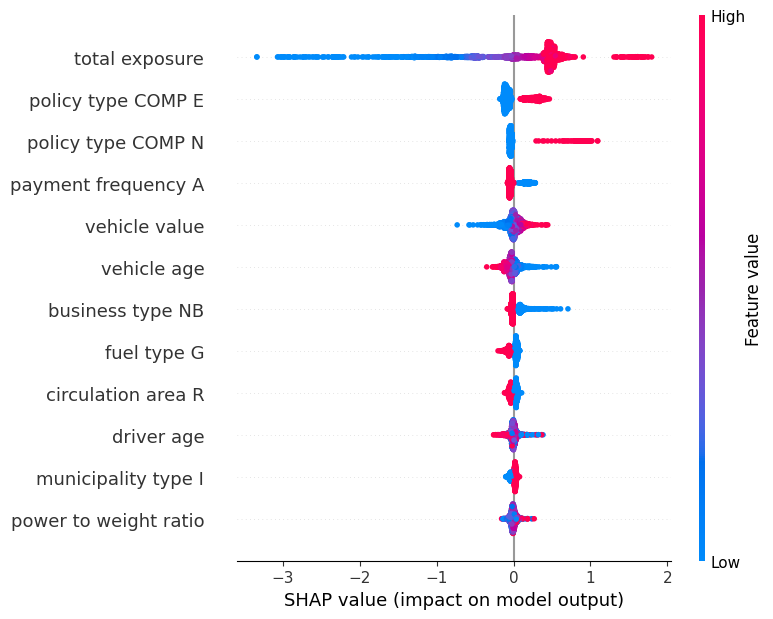

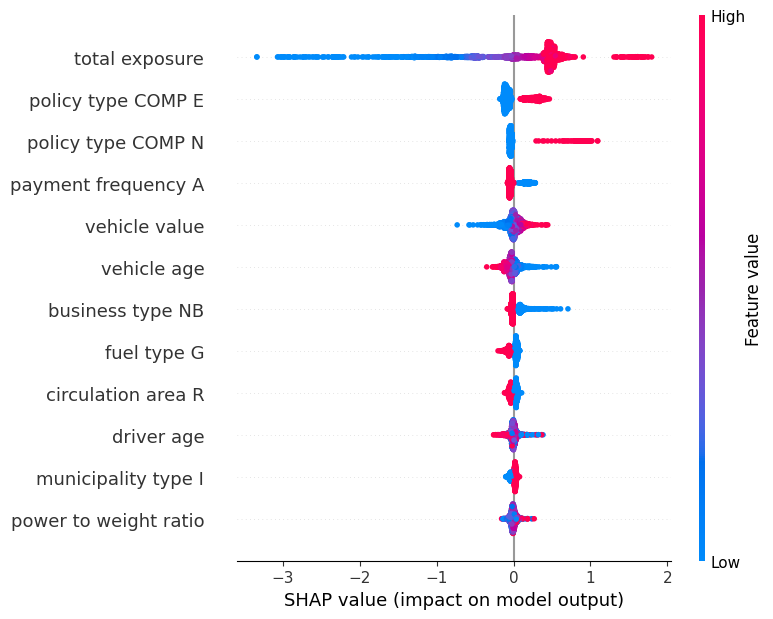

In [7]:
import shap

sample = test.sample(2000, random_state=config.RANDOM_STATE)
cols = config.FEATURES + [config.EXPOSURE_COL]
transformed = models["lgbm"].named_steps["preprocess"].transform(sample[cols])
if hasattr(transformed, "toarray"):
    transformed = transformed.toarray()
raw_names = models["lgbm"].named_steps["preprocess"].get_feature_names_out()
explainer = shap.TreeExplainer(models["lgbm"].named_steps["model"])
shap_values = explainer.shap_values(transformed)
if isinstance(shap_values, list):
    shap_values = shap_values[1]

def pretty(name):
    rest = name.split("__", 1)[1]
    return rest.replace("_", " ")

plt.figure()
shap.summary_plot(
    shap_values,
    transformed,
    feature_names=[pretty(name) for name in raw_names],
    max_display=12,
    show=False,
)
fig = plt.gcf()
fig.tight_layout()
fig.savefig(Path("..") / "reports" / "figures" / "shap_summary.png", dpi=150, bbox_inches="tight")
fig

## 5. Fairness check

Since 2012, EU insurers cannot use gender to set prices. Gender is not one of the model features. The check below asks whether the file even has a gender column, so a with-versus-without comparison could be run.

It does not. None of the 47 columns is sex, gender, or a Spanish equivalent. The model cannot be refit with and without gender, and a difference in predictions for women and men cannot be measured from this file.

What the file does contain can still stand in for a social pattern. Past claims, payment schedule, and home area all move the claim rate a little. Those are facts about the policy, not a gender label, and they stay in the model because they are known on the first day of the year.

In [8]:
header = pd.read_csv(config.RAW_DIR / config.RAW_DATA_FILE, sep=";", nrows=0).columns
gender_columns = [
    name for name in header
    if any(word in name.lower() for word in ("sex", "gender", "sexo", "genero"))
]
print(f"Columns in the raw file: {len(header)}")
print("Gender columns:", gender_columns if len(gender_columns) else "none")

Columns in the raw file: 47
Gender columns: none


## 6. Risk tiers

Low, Medium, and High are the lower, middle, and upper third of LightGBM scores on these 2024 policies. The app uses the same idea on a full next year, which is why `RISK_TIER_CUTOFFS` in `src/config.py` sit at about 14.1% and 19.6%.

In [9]:
low, medium = np.quantile(p_lgbm, [1 / 3, 2 / 3])
tiers = assign_risk_tier(p_lgbm, {"Low": float(low), "Medium": float(medium)})
pd.DataFrame({"tier": tiers, "actual": y}).groupby("tier").agg(
    policies=("actual", "size"), actual_claim_rate=("actual", "mean"))

,policies,actual_claim_rate
tier,,
High,55951,0.251970
Low,55951,0.065075
Medium,55951,0.137209


## 7. Final model choice

The app uses LightGBM.

On 2024, LightGBM has the best sorting score and a small calibration gap: AUC 0.692, Gini 0.384, calibration gap 0.003. XGBoost is next at 0.683. The GLM and the random forest are both 0.679, but the forest's probabilities sit farther from the real claim rate (gap 0.019). Logistic regression is 0.676 and the single tree is 0.663. LightGBM's lead over XGBoost is 0.009, so it stays the model in the app.

LightGBM adds hundreds of small trees. Each new tree corrects the policies the earlier trees scored too high or too low. About 53% of its splits use time on cover, 15% use coverage, 6% use vehicle value, and 5% use vehicle age. The app asks about a full next year, so time on cover is fixed at 1 and the other facts are what change from one driver to the next. The GLM remains the model to read when you want a single percentage effect for vehicle value or vehicle age.